# TLB Risk Prediction from Daily Weather Data (Nepal, 1981-2019)

Late blight (TLB) of potato and tomato spreads fast when the air is very humid and nights are cool.
In this notebook I use daily weather for 62 districts of Nepal to predict whether the **next day**
will have TLB-favourable conditions.

Steps:
1. Load data and EDA
2. Date and season features
3. Making the TLB label
4. Feature engineering (lags, rolling windows, humid streak)
5. Train / validation / test split by year
6. Baseline models
7. Random Forest, XGBoost and CatBoost
8. XGBoost tuning
9. Model comparison
10. Feature importance and SHAP
11. Risk by district and season

**Note on the earlier version:** in the first notebook the label was made from `RH_2m` and `MinTemp_2m`
of the same day and `RH_2m` was also used as a feature, so every model got ~0.99 which is not real
prediction. Here the target is the condition on the next day, the split is done by year (no future data
in training), and scaling/class weights are fitted only on the training data.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             roc_curve, precision_recall_curve)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import shap
import joblib

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# settings
DATA_PATH = "data/dailyweather.csv"
OUT_DIR = "outputs"
SEED = 42

os.makedirs(OUT_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 1. Loading the dataset

In [3]:
df = pd.read_csv(DATA_PATH, index_col=0)   # first column is just the old row index
df["Date"] = pd.to_datetime(df["Date"])

print("Shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Districts:", df["District"].nunique())
df.head()

Shape: (883128, 22)
Date range: 1981-01-01 to 2019-12-31
Districts: 62


,Date,District,Latitude,Longitude,Precip,Pressure,Humidity_2m,RH_2m,Temp_2m,WetBulbTemp_2m,MaxTemp_2m,MinTemp_2m,TempRange_2m,EarthSkinTemp,WindSpeed_10m,MaxWindSpeed_10m,MinWindSpeed_10m,WindSpeedRange_10m,WindSpeed_50m,MaxWindSpeed_50m,MinWindSpeed_50m,WindSpeedRange_50m
0,1981-01-01,Arghakhanchi,27.9,83.2,0.00,93.51,4.81,45.41,13.89,2.15,20.82,9.94,10.89,11.32,1.89,3.83,0.69,3.14,2.41,4.12,0.73,3.39
1,1981-01-02,Arghakhanchi,27.9,83.2,0.00,93.59,4.94,46.78,13.84,2.54,20.70,9.54,11.17,11.44,1.72,2.60,1.09,1.50,2.25,3.30,0.96,2.34
2,1981-01-03,Arghakhanchi,27.9,83.2,0.03,93.55,5.22,47.91,14.33,3.32,20.71,10.78,9.93,12.24,1.80,2.80,0.48,2.32,2.32,3.54,0.39,3.15
3,1981-01-04,Arghakhanchi,27.9,83.2,0.02,93.49,5.36,50.83,13.82,3.73,20.43,10.02,10.41,12.17,2.18,3.54,1.06,2.49,2.90,4.05,0.93,3.12
4,1981-01-05,Arghakhanchi,27.9,83.2,1.84,93.49,5.84,55.55,13.76,4.93,19.62,9.08,10.53,12.32,1.96,2.70,0.69,2.02,2.74,4.64,0.96,3.68


## 2. EDA

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 883128 entries, 0 to 883127
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Date                883128 non-null  datetime64[us]
 1   District            883128 non-null  str           
 2   Latitude            883128 non-null  float64       
 3   Longitude           883128 non-null  float64       
 4   Precip              883128 non-null  float64       
 5   Pressure            883128 non-null  float64       
 6   Humidity_2m         883128 non-null  float64       
 7   RH_2m               883128 non-null  float64       
 8   Temp_2m             883128 non-null  float64       
 9   WetBulbTemp_2m      883128 non-null  float64       
 10  MaxTemp_2m          883128 non-null  float64       
 11  MinTemp_2m          883128 non-null  float64       
 12  TempRange_2m        883128 non-null  float64       
 13  EarthSkinTemp       883128 non-null  flo

In [5]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,883128,2000-07-01 12:00:00,1981-01-01 00:00:00,1990-10-01 18:00:00,2000-07-01 12:00:00,2010-04-01 06:00:00,2019-12-31 00:00:00,NaN
Latitude,883128.0,27.959677,26.5,27.3,27.95,28.5,30.0,0.883261
Longitude,883128.0,84.277419,80.2,82.4,84.3,85.9,87.9,2.181331
Precip,883128.0,2.433753,0.0,0.0,0.05,1.87,177.79,6.160721
Pressure,883128.0,82.89639,54.73,77.68,83.72,92.74,100.34,10.707984
Humidity_2m,883128.0,8.491043,0.27,3.91,6.75,13.17,23.27,5.426636
RH_2m,883128.0,55.65795,4.04,36.54,54.32,77.16,100.0,22.877576
Temp_2m,883128.0,15.815832,-25.44,10.07,16.73,22.5,38.61,9.172463
WetBulbTemp_2m,883128.0,5.428265,-28.19,-2.74,4.98,14.78,27.15,10.850204
MaxTemp_2m,883128.0,21.856533,-16.94,16.55,22.51,27.94,46.82,8.848121


In [6]:
# checking missing values and duplicate days
print("Missing values:", df.isnull().sum().sum())
print("Duplicate (District, Date) rows:", df.duplicated(["District", "Date"]).sum())

# every district should have the same number of days
print(df.groupby("District").size().describe())

Missing values: 0
Duplicate (District, Date) rows: 0
count       62.0
mean     14244.0
std          0.0
min      14244.0
25%      14244.0
50%      14244.0
75%      14244.0
max      14244.0
dtype: float64


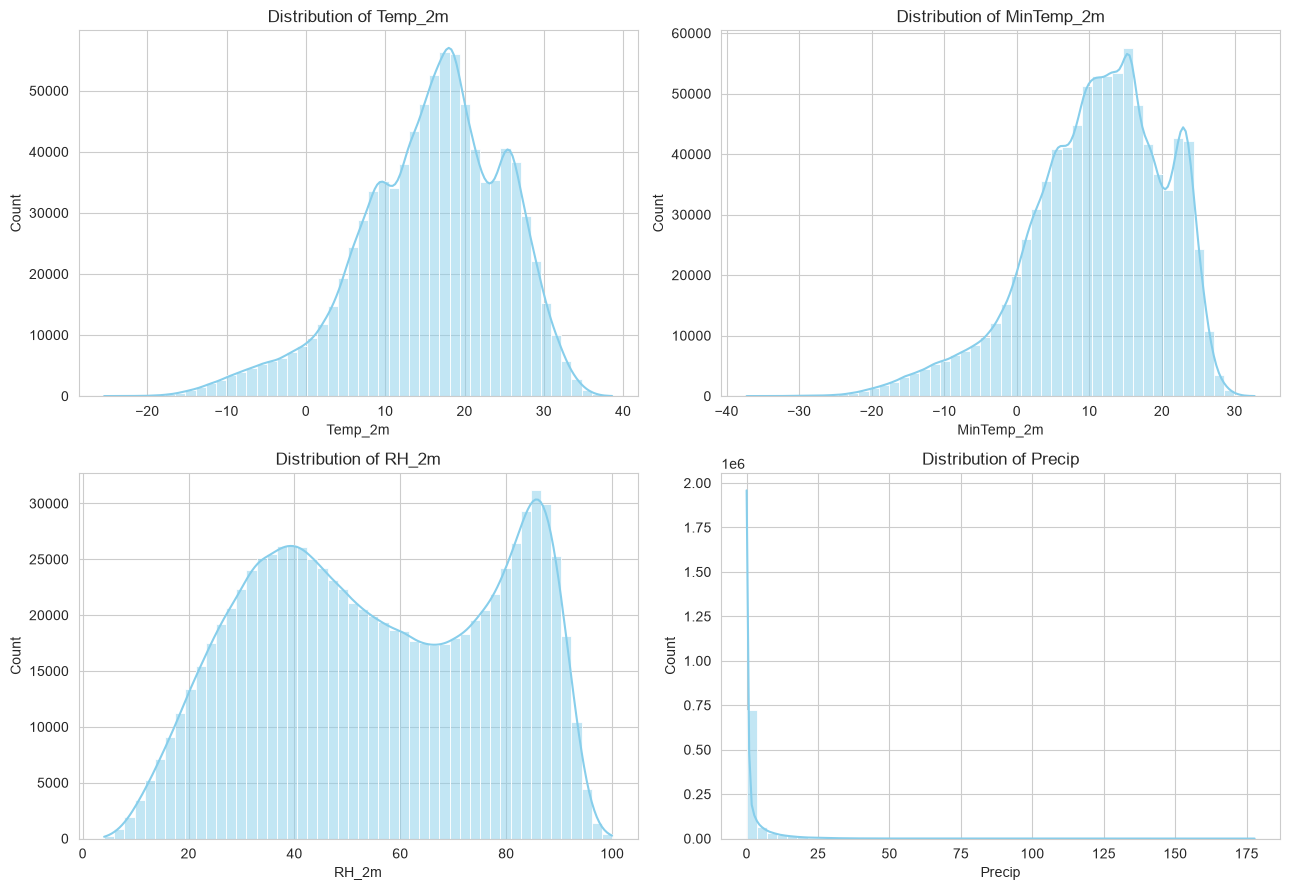

In [7]:
# distribution of main variables
main_vars = ["Temp_2m", "MinTemp_2m", "RH_2m", "Precip"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
for i, col in enumerate(main_vars):
    sns.histplot(df[col], bins=50, kde=True, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}")
plt.tight_layout()
save_fig("eda_distributions")
plt.show()

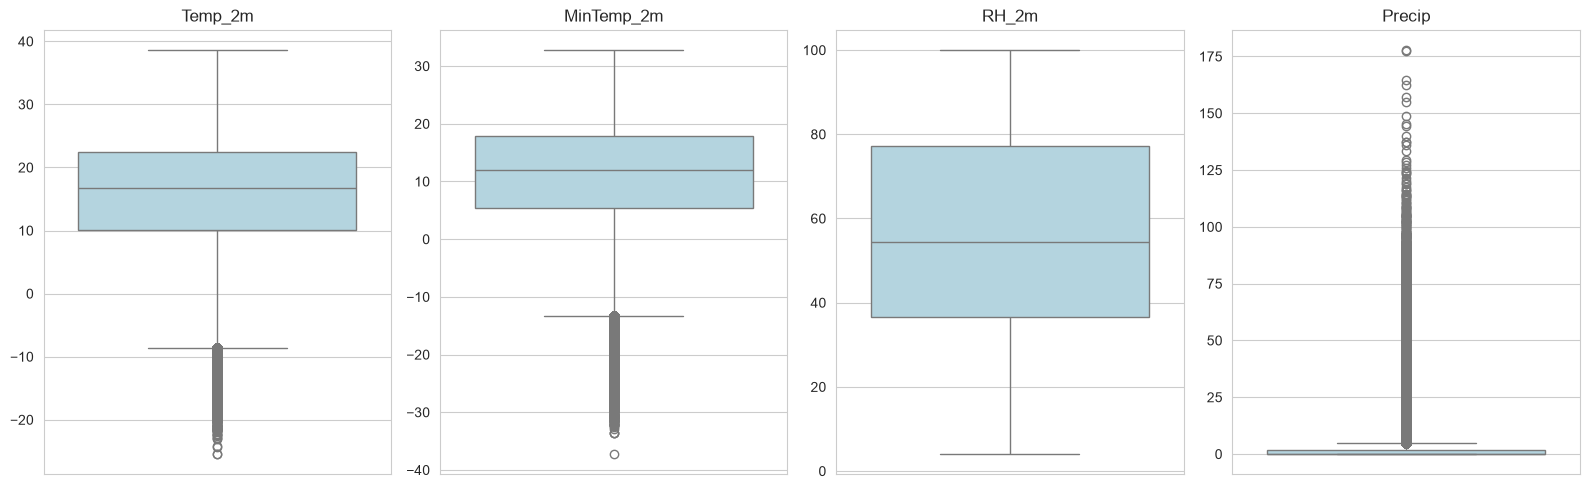

In [8]:
# outliers
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for i, col in enumerate(main_vars):
    sns.boxplot(y=df[col], ax=axes[i], color="lightblue")
    axes[i].set_title(col)
    axes[i].set_ylabel("")
plt.tight_layout()
plt.show()

Precip is very right skewed (most days ~0 and a few very heavy rain days). These are real monsoon
values, not errors, so I keep them. Tree models are not affected much by skew.

## 3. Date and season features

In [9]:
df = df.sort_values(["District", "Date"]).reset_index(drop=True)

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfYear"] = df["Date"].dt.dayofyear

def nepal_season(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Pre-Monsoon"
    elif m in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

season_order = ["Winter", "Pre-Monsoon", "Monsoon", "Post-Monsoon"]
df["Season"] = df["Month"].apply(nepal_season)
df["Season_encoded"] = df["Season"].map({s: i for i, s in enumerate(season_order)})

# day of year as sin/cos so 31 Dec and 1 Jan are close to each other
df["doy_sin"] = np.sin(2 * np.pi * df["DayOfYear"] / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * df["DayOfYear"] / 365.25)

df["Season"].value_counts()

Season
Monsoon         294996
Pre-Monsoon     222456
Winter          218178
Post-Monsoon    147498
Name: count, dtype: int64

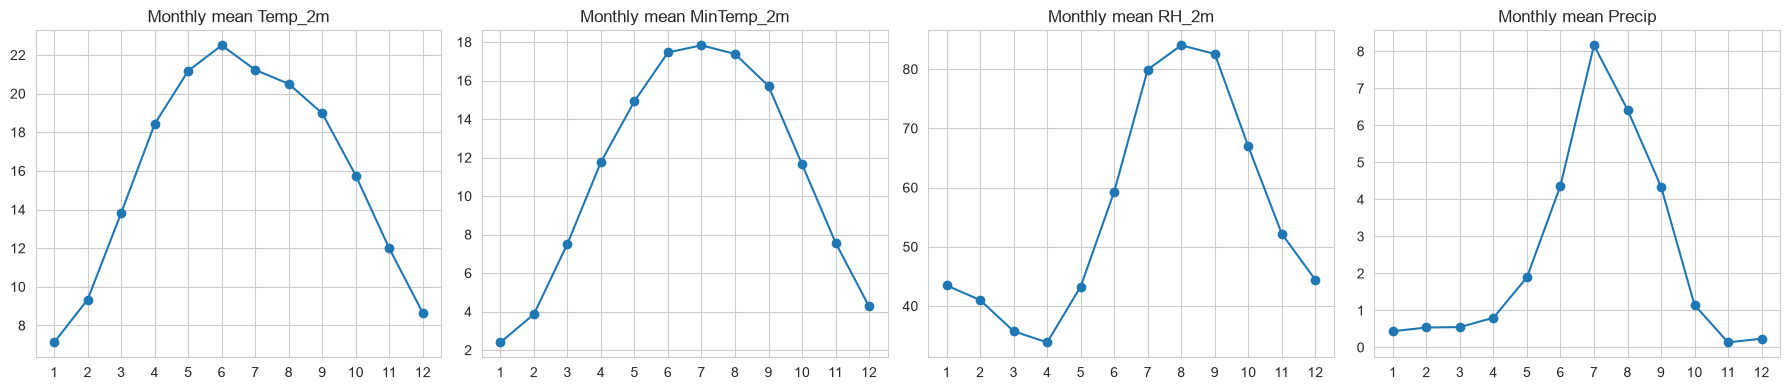

In [10]:
# monthly averages (each variable in its own plot because units are different)
monthly = df.groupby("Month")[main_vars].mean()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(main_vars):
    axes[i].plot(monthly.index, monthly[col], marker="o")
    axes[i].set_title(f"Monthly mean {col}")
    axes[i].set_xticks(range(1, 13))
plt.tight_layout()
save_fig("eda_monthly")
plt.show()

In [11]:
seasonal = df.groupby("Season")[main_vars].mean().reindex(season_order)
seasonal.round(2)

,Temp_2m,MinTemp_2m,RH_2m,Precip
Season,,,,
Winter,8.34,3.50,43.03,0.40
Pre-Monsoon,17.80,11.40,37.66,1.08
Monsoon,20.80,17.11,76.56,5.85
Post-Monsoon,13.90,9.65,59.69,0.65


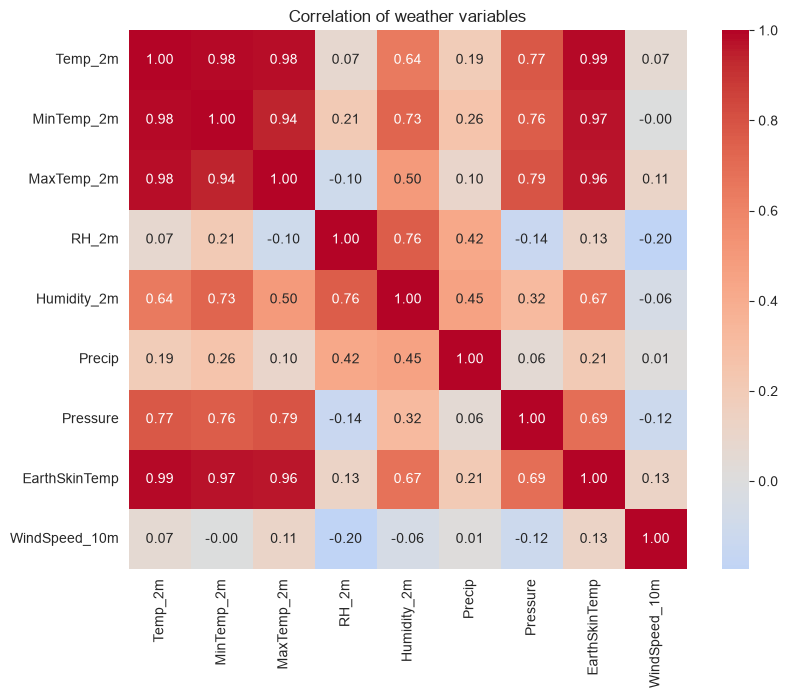

In [12]:
corr_vars = ["Temp_2m", "MinTemp_2m", "MaxTemp_2m", "RH_2m", "Humidity_2m", "Precip",
             "Pressure", "EarthSkinTemp", "WindSpeed_10m"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_vars].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of weather variables")
save_fig("eda_correlation")
plt.show()

## 4. Making the TLB label

There is no field survey data of blight cases, so I use the weather rule commonly used for late
blight: a day is **TLB-favourable** when

- relative humidity > 80 %, and
- minimum temperature < 10 °C

This label is only "favourable conditions", not confirmed disease, so the results should be read as
weather-based risk.

In [13]:
RH_LIMIT = 80
TMIN_LIMIT = 10

df["TLB_today"] = ((df["RH_2m"] > RH_LIMIT) & (df["MinTemp_2m"] < TMIN_LIMIT)).astype(int)

print(df["TLB_today"].value_counts())
print("Positive rate: {:.2%}".format(df["TLB_today"].mean()))

TLB_today
0    853833
1     29295
Name: count, dtype: int64
Positive rate: 3.32%


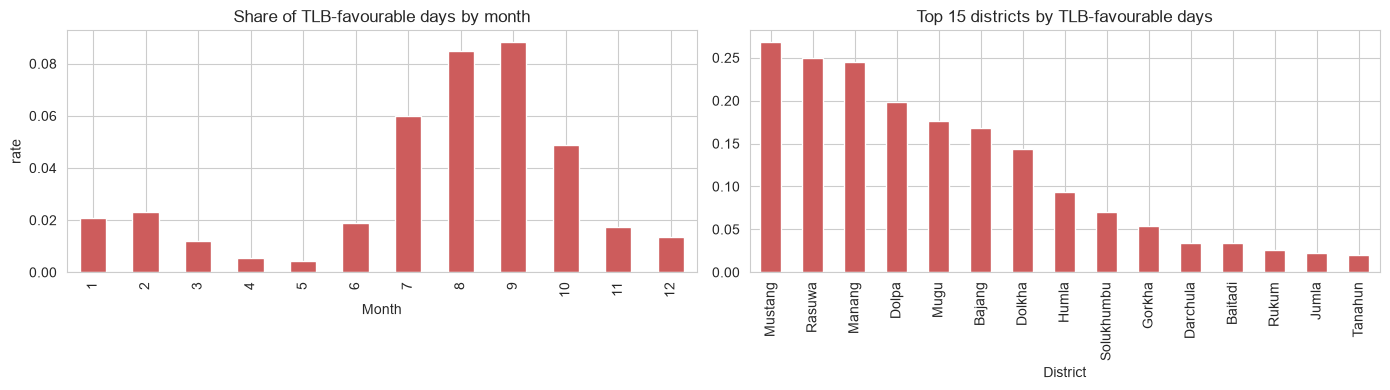

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df.groupby("Month")["TLB_today"].mean().plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("Share of TLB-favourable days by month")
axes[0].set_ylabel("rate")

top_d = df.groupby("District")["TLB_today"].mean().sort_values(ascending=False).head(15)
top_d.plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Top 15 districts by TLB-favourable days")
plt.tight_layout()
save_fig("label_month_district")
plt.show()

Only ~3% of days are positive, so the data is imbalanced. Most positive days are in the monsoon
(Jul-Sep) in the cold, high mountain districts where humidity is high and nights stay below 10 °C.

**Target:** I want to warn farmers in advance, so the target is the label of the **next day**
(`TLB_next`) for the same district, using only today's and past weather.

In [15]:
HORIZON = 1   # days ahead

df["TLB_next"] = df.groupby("District")["TLB_today"].shift(-HORIZON)

## 5. Feature engineering

In [16]:
g = df.groupby("District")

# yesterday and the day before
for col in ["RH_2m", "MinTemp_2m", "Temp_2m", "Precip"]:
    df[f"{col}_lag1"] = g[col].shift(1)
    df[f"{col}_lag2"] = g[col].shift(2)

# rolling means over last 3 and 7 days (today included)
for col in ["RH_2m", "MinTemp_2m", "Precip", "Temp_2m"]:
    for w in [3, 7]:
        df[f"{col}_mean{w}"] = g[col].transform(lambda x: x.rolling(w, min_periods=w).mean())

df["Precip_sum7"] = g["Precip"].transform(lambda x: x.rolling(7, min_periods=7).sum())

# humid streak: 3 days in a row with RH > 80
df["humid_day"] = (df["RH_2m"] > RH_LIMIT).astype(int)
df["humid_streak3"] = (g["humid_day"].transform(lambda x: x.rolling(3, min_periods=3).sum()) == 3).astype(int)
df["humid_days7"] = g["humid_day"].transform(lambda x: x.rolling(7, min_periods=7).sum())

# how many favourable days in last 7 days
df["tlb_days7"] = g["TLB_today"].transform(lambda x: x.rolling(7, min_periods=7).sum())

# change from yesterday
df["RH_change"] = df["RH_2m"] - df["RH_2m_lag1"]
df["MinTemp_change"] = df["MinTemp_2m"] - df["MinTemp_2m_lag1"]

# rows at the start (no lag) or end (no next day) of each district are dropped
before = len(df)
df = df.dropna().reset_index(drop=True)
df["TLB_next"] = df["TLB_next"].astype(int)
print("Dropped", before - len(df), "rows. Remaining:", len(df))

Dropped 434 rows. Remaining: 882694


In [17]:
weather_cols = ["Precip", "Pressure", "RH_2m", "Humidity_2m", "Temp_2m", "WetBulbTemp_2m",
                "MaxTemp_2m", "MinTemp_2m", "TempRange_2m", "EarthSkinTemp",
                "WindSpeed_10m", "WindSpeed_50m"]

eng_cols = [c for c in df.columns if c.endswith(("_lag1", "_lag2", "_mean3", "_mean7"))]
eng_cols += ["Precip_sum7", "humid_streak3", "humid_days7", "tlb_days7", "RH_change", "MinTemp_change"]

# location and time (Latitude/Longitude instead of 62 one-hot district columns)
other_cols = ["Latitude", "Longitude", "Month", "Season_encoded", "doy_sin", "doy_cos", "TLB_today"]

features = weather_cols + eng_cols + other_cols
target = "TLB_next"

print(len(features), "features")

41 features


## 6. Train / validation / test split by year

Weather on nearby days is very similar, so a random split would put almost the same day in train and
test and give over-optimistic scores. I split by time instead:

| set | years | use |
|---|---|---|
| train | 1981-2011 | fit models |
| validation | 2012-2015 | tuning and picking the threshold |
| test | 2016-2019 | final results only |

In [18]:
train = df[df["Year"] <= 2011]
val = df[(df["Year"] >= 2012) & (df["Year"] <= 2015)]
test = df[df["Year"] >= 2016]

X_train, y_train = train[features].astype("float32"), train[target]
X_val, y_val = val[features].astype("float32"), val[target]
X_test, y_test = test[features].astype("float32"), test[target]

for name, y_part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: {len(y_part):7d} rows, positive rate {y_part.mean():.2%}")

train:  701592 rows, positive rate 2.82%
val  :   90582 rows, positive rate 5.62%
test :   90520 rows, positive rate 4.87%


For imbalance I use class weights (`class_weight` / `scale_pos_weight`) instead of SMOTE. SMOTE makes
synthetic days by mixing neighbours, which does not make much sense for time series, and in the old
version it was applied before the split.

Because positives are rare, accuracy is not useful (predicting always 0 gives ~97%). I mainly look at
**F1, recall, PR-AUC** and ROC-AUC. The probability threshold is chosen on the validation set (best
F1) and then used as it is on the test set.

In [19]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("neg/pos ratio:", round(pos_weight, 1))

def best_threshold(y_true, prob):
    prec, rec, thr = precision_recall_curve(y_true, prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    i = np.argmax(f1[:-1])
    return thr[i]

def get_scores(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {
        "Model": name,
        "Threshold": thr,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "PR_AUC": average_precision_score(y_true, prob),
    }

results = []        # test scores of each model
test_probs = {}     # test probabilities for plots

def evaluate(name, model):
    p_val = model.predict_proba(X_val)[:, 1]
    p_test = model.predict_proba(X_test)[:, 1]
    thr = best_threshold(y_val, p_val)
    s = get_scores(name, y_test, p_test, thr)
    results.append(s)
    test_probs[name] = p_test
    print(f"{name}: threshold={thr:.3f}  F1={s['F1']:.4f}  Recall={s['Recall']:.4f}  "
          f"Precision={s['Precision']:.4f}  PR_AUC={s['PR_AUC']:.4f}  ROC_AUC={s['ROC_AUC']:.4f}")

neg/pos ratio: 34.5


## 7. Baseline models

**Persistence baseline:** "tomorrow will be the same as today". Weather is persistent, so this is a
strong and honest baseline that any ML model should beat.

In [20]:
# persistence: prediction for tomorrow = today's label
persist = get_scores("Persistence (today = tomorrow)", y_test, test["TLB_today"].values, 0.5)
results.append(persist)
test_probs["Persistence (today = tomorrow)"] = test["TLB_today"].values.astype(float)

pd.Series(persist).drop("Model")

Threshold         0.5
Accuracy     0.972415
Precision    0.717007
Recall       0.716844
F1           0.716926
ROC_AUC      0.851175
PR_AUC        0.52778
dtype: object

In [21]:
# logistic regression (needs scaling, scaler is fitted inside the pipeline on train only)
logreg = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)
evaluate("Logistic Regression", logreg)

Logistic Regression: threshold=0.966  F1=0.7114  Recall=0.7291  Precision=0.6946  PR_AUC=0.7397  ROC_AUC=0.9798


In [22]:
dtree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced", random_state=SEED)
dtree.fit(X_train, y_train)
evaluate("Decision Tree", dtree)

Decision Tree: threshold=0.956  F1=0.7327  Recall=0.7549  Precision=0.7117  PR_AUC=0.7829  ROC_AUC=0.9673


## 8. Random Forest, XGBoost and CatBoost

In [23]:
%%time
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    max_features="sqrt",
    max_samples=0.5,          # each tree sees half the rows, much faster on 700k rows
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

Random Forest: threshold=0.597  F1=0.7360  Recall=0.7887  Precision=0.6899  PR_AUC=0.8360  ROC_AUC=0.9873
CPU times: user 5min 25s, sys: 4.61 s, total: 5min 30s
Wall time: 45 s


In [24]:
%%time
xgb_base = XGBClassifier(
    n_estimators=400,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    tree_method="hist",
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=SEED,
)
xgb_base.fit(X_train, y_train)
evaluate("XGBoost", xgb_base)

XGBoost: threshold=0.882  F1=0.7422  Recall=0.7518  Precision=0.7330  PR_AUC=0.8350  ROC_AUC=0.9868
CPU times: user 1min 46s, sys: 9.1 s, total: 1min 55s
Wall time: 15.3 s


In [25]:
%%time
cat = CatBoostClassifier(
    iterations=600,
    learning_rate=0.1,
    depth=6,
    auto_class_weights="Balanced",
    eval_metric="PRAUC",
    random_seed=SEED,
    thread_count=-1,
    verbose=0,
)
# validation set used for early stopping
cat.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50)
print("best iteration:", cat.get_best_iteration())
evaluate("CatBoost", cat)

best iteration: 126
CatBoost: threshold=0.911  F1=0.7368  Recall=0.8118  Precision=0.6744  PR_AUC=0.8365  ROC_AUC=0.9879
CPU times: user 1min 34s, sys: 3.99 s, total: 1min 38s
Wall time: 24.4 s


## 9. XGBoost tuning

I try a few parameter combinations, train on the training years and compare on the validation years
(PR-AUC). Early stopping picks the number of trees. The test set is not touched here.

In [26]:
%%time
param_grid = [
    {"max_depth": 4, "learning_rate": 0.05, "min_child_weight": 1,  "subsample": 0.8, "colsample_bytree": 0.8},
    {"max_depth": 6, "learning_rate": 0.05, "min_child_weight": 5,  "subsample": 0.8, "colsample_bytree": 0.8},
    {"max_depth": 8, "learning_rate": 0.05, "min_child_weight": 5,  "subsample": 0.8, "colsample_bytree": 0.6},
    {"max_depth": 6, "learning_rate": 0.03, "min_child_weight": 10, "subsample": 0.7, "colsample_bytree": 0.7},
    {"max_depth": 10, "learning_rate": 0.05, "min_child_weight": 20, "subsample": 0.8, "colsample_bytree": 0.6},
]

tuning_rows = []
best_score, best_model = -1, None

for params in param_grid:
    m = XGBClassifier(
        n_estimators=2000,
        scale_pos_weight=pos_weight,
        tree_method="hist",
        eval_metric="aucpr",
        early_stopping_rounds=50,
        n_jobs=-1,
        random_state=SEED,
        **params,
    )
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    p_val = m.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, p_val)
    tuning_rows.append({**params, "best_trees": m.best_iteration + 1, "val_PR_AUC": score})
    print(params, "-> trees:", m.best_iteration + 1, " val PR_AUC: {:.4f}".format(score))

    if score > best_score:
        best_score, best_model = score, m

tuning_df = pd.DataFrame(tuning_rows).sort_values("val_PR_AUC", ascending=False)
tuning_df.to_csv(f"{OUT_DIR}/xgb_tuning.csv", index=False)
tuning_df

{'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 1, 'subsample': 0.8, 'colsample_bytree': 0.8} -> trees: 254  val PR_AUC: 0.8203


{'max_depth': 6, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8} -> trees: 175  val PR_AUC: 0.8239


{'max_depth': 8, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.6} -> trees: 91  val PR_AUC: 0.8236


{'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 10, 'subsample': 0.7, 'colsample_bytree': 0.7} -> trees: 255  val PR_AUC: 0.8254


{'max_depth': 10, 'learning_rate': 0.05, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.6} -> trees: 100  val PR_AUC: 0.8259
CPU times: user 8min 41s, sys: 36.3 s, total: 9min 17s
Wall time: 1min 18s


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,best_trees,val_PR_AUC
4,10,0.05,20,0.8,0.6,100,0.825923
3,6,0.03,10,0.7,0.7,255,0.825398
1,6,0.05,5,0.8,0.8,175,0.823906
2,8,0.05,5,0.8,0.6,91,0.823568
0,4,0.05,1,0.8,0.8,254,0.820286


In [27]:
xgb_tuned = best_model
evaluate("XGBoost (tuned)", xgb_tuned)

XGBoost (tuned): threshold=0.878  F1=0.7444  Recall=0.7908  Precision=0.7032  PR_AUC=0.8409  ROC_AUC=0.9878


## 10. Model comparison (test set 2016-2019)

In [28]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df = results_df.sort_values("PR_AUC", ascending=False)
results_df.to_csv(f"{OUT_DIR}/model_comparison.csv")
results_df

,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,,
XGBoost (tuned),0.8776,0.9735,0.7032,0.7908,0.7444,0.9878,0.8409
CatBoost,0.9106,0.9717,0.6744,0.8118,0.7368,0.9879,0.8365
Random Forest,0.5975,0.9724,0.6899,0.7887,0.7360,0.9873,0.8360
XGBoost,0.8818,0.9746,0.7330,0.7518,0.7422,0.9868,0.8350
Decision Tree,0.9557,0.9732,0.7117,0.7549,0.7327,0.9673,0.7829
Logistic Regression,0.9656,0.9712,0.6946,0.7291,0.7114,0.9798,0.7397
Persistence (today = tomorrow),0.5000,0.9724,0.7170,0.7168,0.7169,0.8512,0.5278


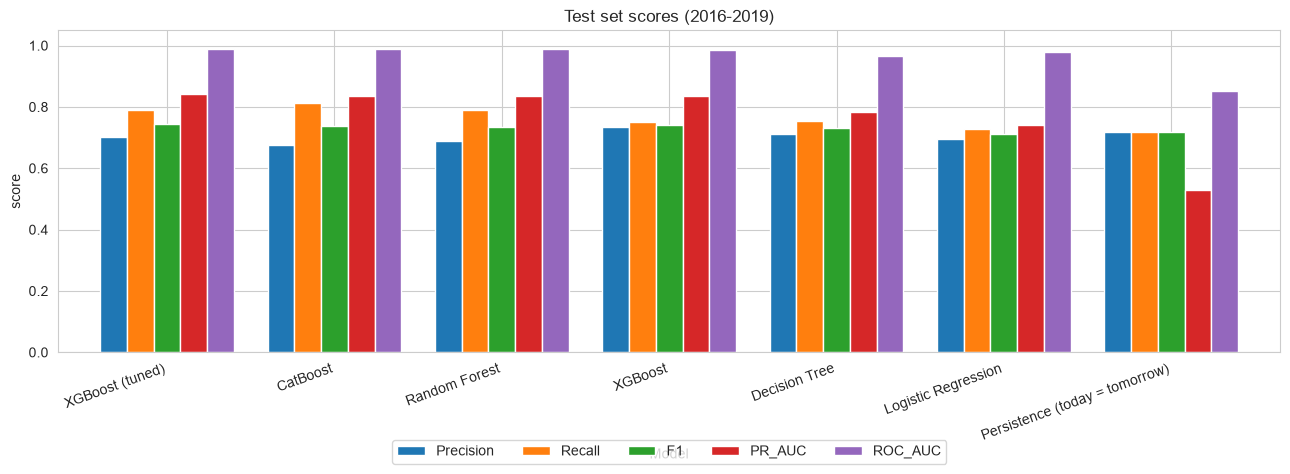

In [29]:
plot_cols = ["Precision", "Recall", "F1", "PR_AUC", "ROC_AUC"]
results_df[plot_cols].plot(kind="bar", figsize=(13, 5), width=0.8)
plt.title("Test set scores (2016-2019)")
plt.ylabel("score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5)
plt.tight_layout()
save_fig("model_comparison")
plt.show()

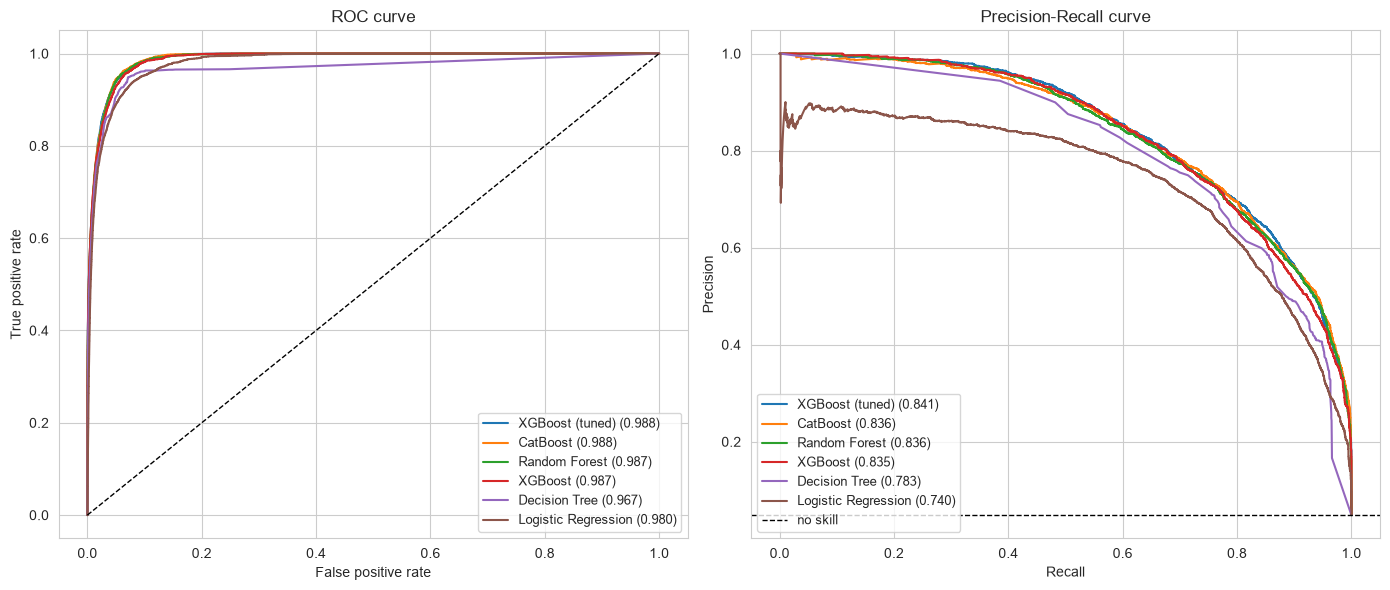

In [30]:
# ROC and Precision-Recall curves (persistence left out because it only gives 0/1)
ml_models = [m for m in results_df.index if not m.startswith("Persistence")]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in ml_models:
    p = test_probs[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="no skill")
axes[1].set_title("Precision-Recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
save_fig("roc_pr_curves")
plt.show()

Best model: XGBoost (tuned)  threshold: 0.878
              precision    recall  f1-score   support

           0     0.9892    0.9829    0.9860     86109
           1     0.7032    0.7908    0.7444      4411

    accuracy                         0.9735     90520
   macro avg     0.8462    0.8868    0.8652     90520
weighted avg     0.9753    0.9735    0.9743     90520



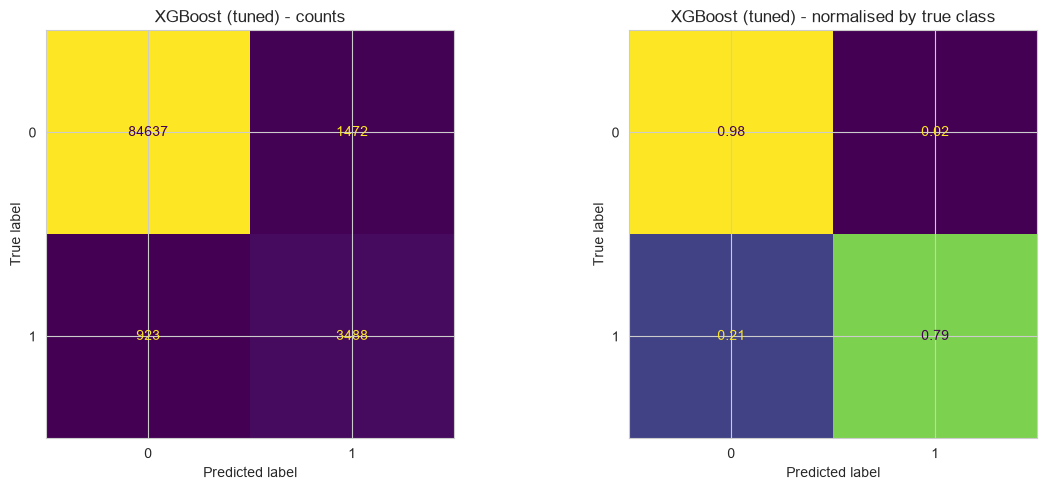

In [31]:
# details for the best model
best_name = results_df.drop(index=[i for i in results_df.index if i.startswith("Persistence")]).index[0]
models = {"Logistic Regression": logreg, "Decision Tree": dtree, "Random Forest": rf,
          "XGBoost": xgb_base, "CatBoost": cat, "XGBoost (tuned)": xgb_tuned}
final_model = models[best_name]
final_thr = results_df.loc[best_name, "Threshold"]
print("Best model:", best_name, " threshold:", round(final_thr, 3))

test_pred = (test_probs[best_name] >= final_thr).astype(int)
print(classification_report(y_test, test_pred, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred)).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title(f"{best_name} - counts")
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred, normalize="true")).plot(ax=axes[1], values_format=".2f", colorbar=False)
axes[1].set_title(f"{best_name} - normalised by true class")
plt.tight_layout()
save_fig("confusion_matrix_best")
plt.show()

In [32]:
# is the model stable across the test years?
yearly = []
for yr in sorted(test["Year"].unique()):
    mask = (test["Year"] == yr).values
    yearly.append(get_scores(yr, y_test[mask], test_probs[best_name][mask], final_thr))

pd.DataFrame(yearly).rename(columns={"Model": "Year"}).set_index("Year").drop(columns="Threshold").round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Year,,,,,,
2016,0.9804,0.7217,0.8522,0.7815,0.9925,0.8832
2017,0.9754,0.6941,0.8238,0.7534,0.9885,0.8544
2018,0.9807,0.7306,0.8493,0.7855,0.9927,0.8800
2019,0.9576,0.6777,0.6931,0.6853,0.9769,0.7734


## 11. Feature importance and SHAP

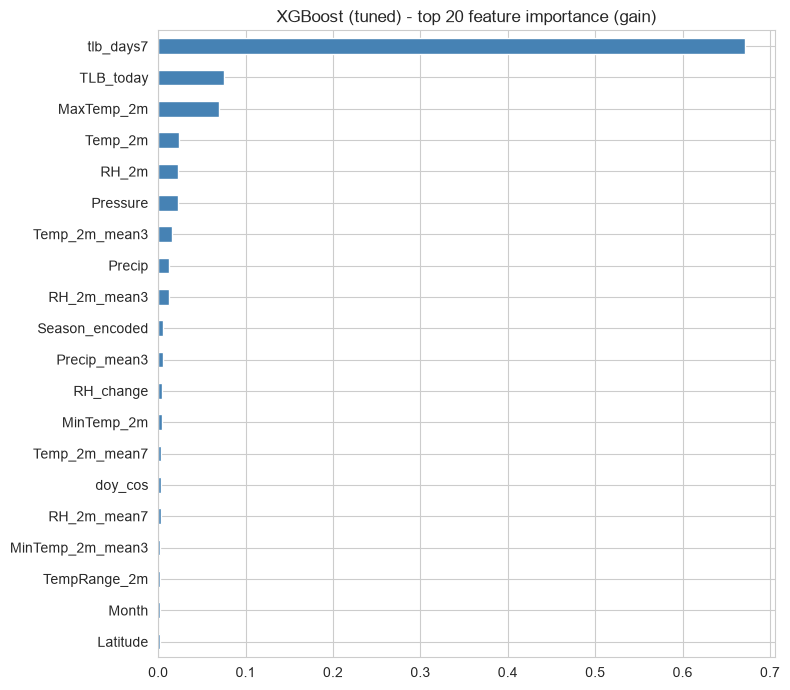

In [33]:
imp = pd.Series(xgb_tuned.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
imp.head(20).sort_values().plot(kind="barh", color="steelblue")
plt.title("XGBoost (tuned) - top 20 feature importance (gain)")
plt.tight_layout()
save_fig("feature_importance")
plt.show()

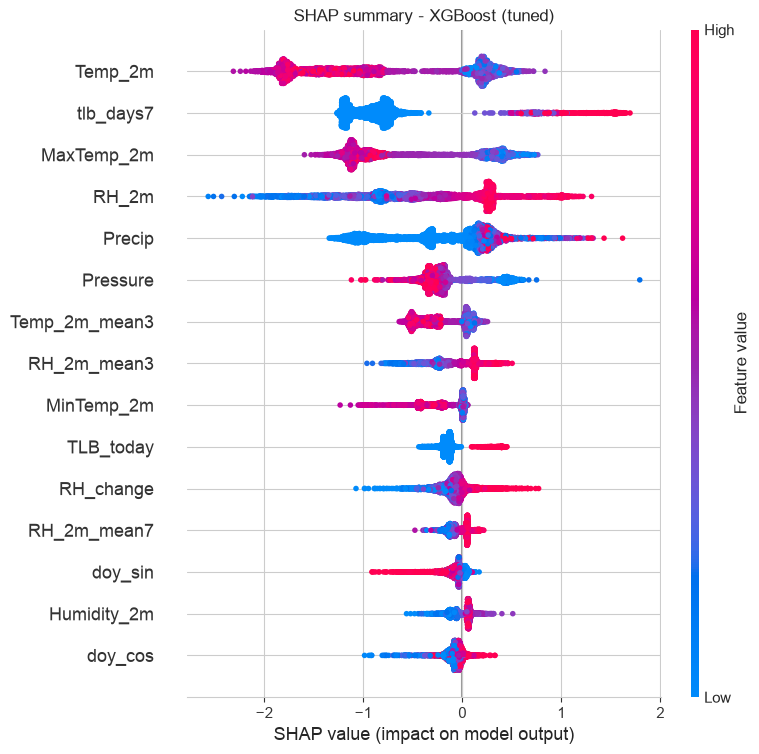

In [34]:
# SHAP on a sample of test rows (whole test set is slow)
sample = X_test.sample(5000, random_state=SEED)

explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, sample, max_display=15, show=False)
plt.title("SHAP summary - XGBoost (tuned)")
save_fig("shap_summary")
plt.show()

- **Temperature** (Temp_2m, MaxTemp_2m) is the strongest: low temperature pushes risk up. This is
  how the model knows the cold mountain districts.
- **tlb_days7** (favourable days in the last week) is next, so recent history matters a lot.
- High **RH** and rain push risk up, as expected.
- **Pressure** works like an altitude proxy: low pressure = high district = more risk.

## 12. Risk by district and season (test period)

In [35]:
risk_df = test[["District", "Latitude", "Longitude", "Season", "Month", "Year", "TLB_next"]].copy()
risk_df["Pred_Risk"] = test_probs[best_name]

dist_risk = (risk_df.groupby(["District", "Latitude", "Longitude"], as_index=False)
             .agg(Mean_Risk=("Pred_Risk", "mean"), Observed_Rate=("TLB_next", "mean"))
             .sort_values("Mean_Risk", ascending=False))
dist_risk.to_csv(f"{OUT_DIR}/district_risk.csv", index=False)
dist_risk.head(10).round(4)

,District,Latitude,Longitude,Mean_Risk,Observed_Rate
34,Manang,28.6,84.2,0.5986,0.4260
37,Mustang,28.9,83.8,0.5706,0.3904
45,Rasuwa,28.1,85.3,0.5206,0.3178
17,Dolpa,29.0,82.9,0.5016,0.3034
36,Mugu,29.5,82.1,0.4891,0.2842
3,Bajang,29.6,81.2,0.4422,0.2336
21,Humla,30.0,81.8,0.4210,0.1568
16,Dolkha,27.6,86.2,0.3917,0.1541
54,Solukhumbu,28.0,86.8,0.2960,0.1479
19,Gorkha,28.0,84.6,0.2092,0.0863


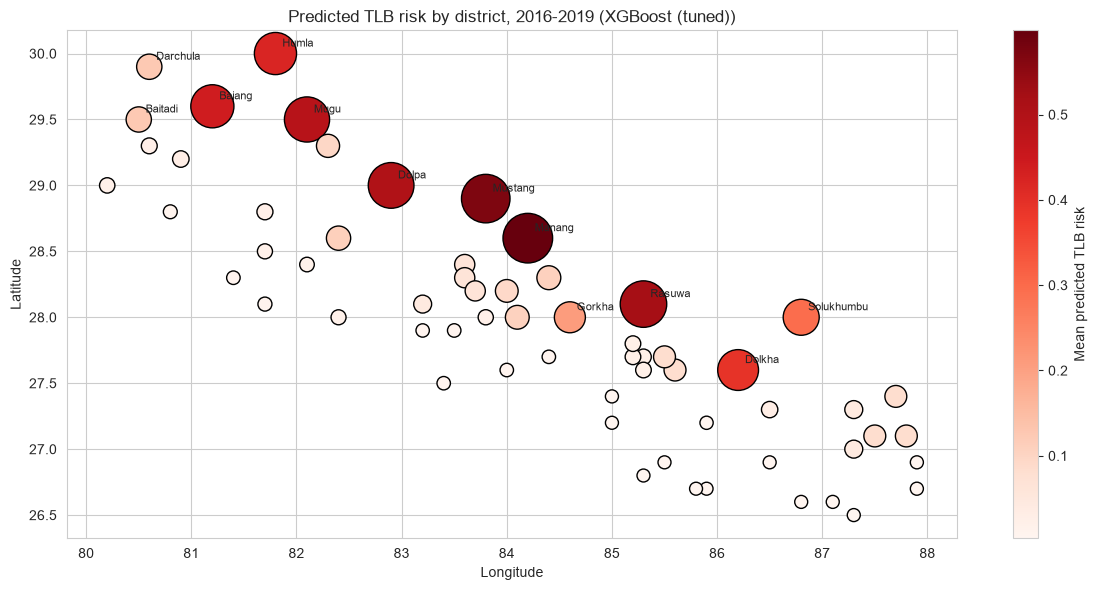

In [36]:
# district locations coloured by mean predicted risk
plt.figure(figsize=(12, 6))
sc = plt.scatter(dist_risk["Longitude"], dist_risk["Latitude"], c=dist_risk["Mean_Risk"],
                 s=80 + 2000 * dist_risk["Mean_Risk"], cmap="Reds", edgecolor="k")
for _, r in dist_risk.head(12).iterrows():
    plt.annotate(r["District"], (r["Longitude"], r["Latitude"]), xytext=(5, 5),
                 textcoords="offset points", fontsize=8)
plt.colorbar(sc, label="Mean predicted TLB risk")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Predicted TLB risk by district, 2016-2019 ({best_name})")
plt.tight_layout()
save_fig("risk_map")
plt.show()

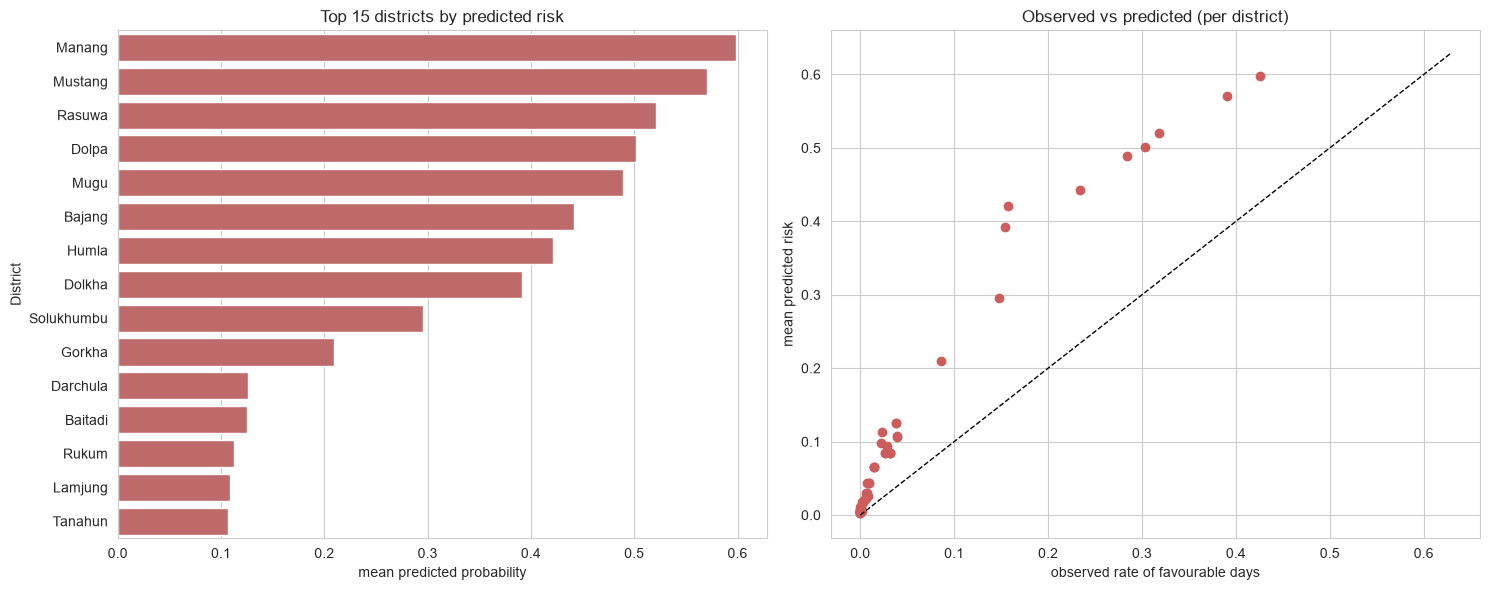

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top15 = dist_risk.head(15)
sns.barplot(data=top15, y="District", x="Mean_Risk", ax=axes[0], color="indianred")
axes[0].set_title("Top 15 districts by predicted risk")
axes[0].set_xlabel("mean predicted probability")

axes[1].scatter(dist_risk["Observed_Rate"], dist_risk["Mean_Risk"], color="indianred")
lim = max(dist_risk["Observed_Rate"].max(), dist_risk["Mean_Risk"].max()) * 1.05
axes[1].plot([0, lim], [0, lim], "k--", lw=1)
axes[1].set_xlabel("observed rate of favourable days")
axes[1].set_ylabel("mean predicted risk")
axes[1].set_title("Observed vs predicted (per district)")

plt.tight_layout()
save_fig("risk_top_districts")
plt.show()

The predicted risk is higher than the observed rate because of the class weights (the model is pushed
to find positives). The ranking of districts is what matters here and it follows the observed rate well.

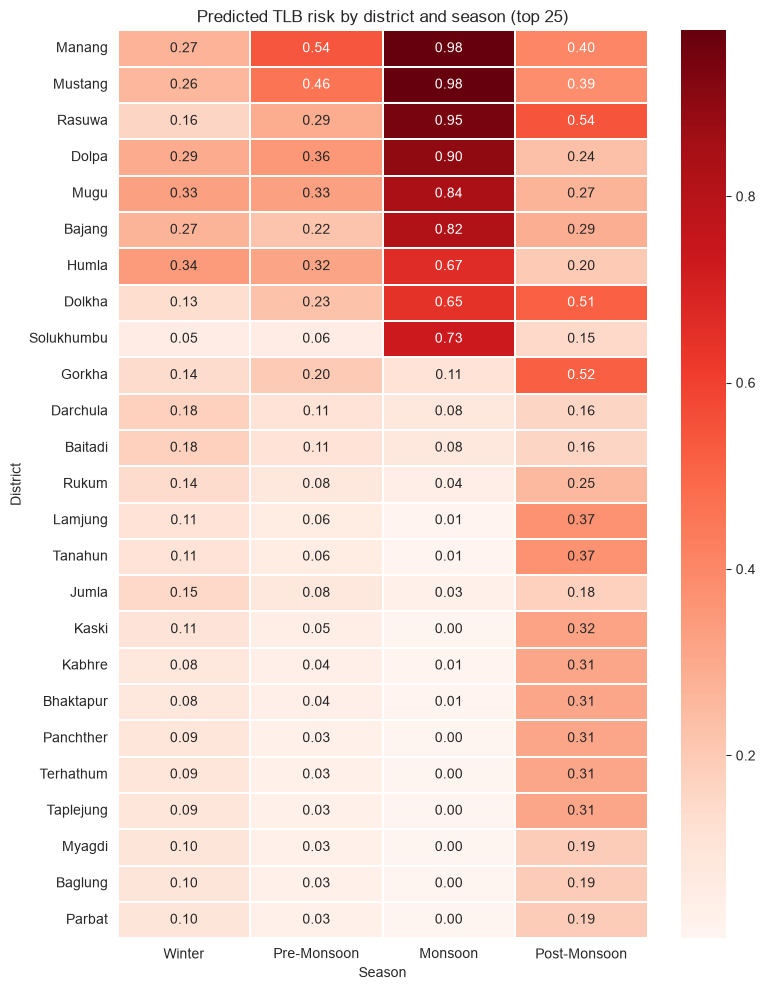

In [38]:
# district x season heatmap for the top 25 districts
top25 = dist_risk.head(25)["District"]
pivot = (risk_df[risk_df["District"].isin(top25)]
         .pivot_table(index="District", columns="Season", values="Pred_Risk", aggfunc="mean")
         .reindex(columns=season_order)
         .loc[top25])

plt.figure(figsize=(8, 10))
sns.heatmap(pivot, cmap="Reds", annot=True, fmt=".2f", linewidths=0.3, linecolor="white")
plt.title("Predicted TLB risk by district and season (top 25)")
plt.tight_layout()
save_fig("risk_district_season")
plt.show()

## 13. Save the final model

In [39]:
if best_name.startswith("XGBoost"):
    final_model.get_booster().save_model(f"{OUT_DIR}/final_model_xgb.json")
else:
    joblib.dump(final_model, f"{OUT_DIR}/final_model.joblib")

joblib.dump({"features": features, "threshold": float(final_thr), "model": best_name},
            f"{OUT_DIR}/final_model_info.joblib")

print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" ", f)

Saved files:
  confusion_matrix_best.png
  district_risk.csv
  eda_correlation.png
  eda_distributions.png
  eda_monthly.png
  feature_importance.png
  final_model_info.joblib
  final_model_xgb.json
  label_month_district.png
  model_comparison.csv
  model_comparison.png
  risk_district_season.png
  risk_map.png
  risk_top_districts.png
  roc_pr_curves.png
  shap_summary.png
  xgb_tuning.csv


## Conclusion

- The TLB label is a weather rule (RH > 80 % and Tmin < 10 °C), so the task is predicting
  next-day favourable conditions, not observed disease.
- With a year-based split and no same-day leakage the scores are realistic. Tuned XGBoost was the
  best on the test years 2016-2019: **F1 = 0.744, recall = 0.79, PR-AUC = 0.841, ROC-AUC = 0.988**.
- The persistence baseline is already strong (F1 = 0.717) because weather changes slowly. The tree
  models beat it a bit in F1 and a lot in PR-AUC (0.53 -> 0.84), so the probabilities are much more
  useful for ranking risk and choosing a warning threshold.
- RF, XGBoost and CatBoost are very close to each other; the gap to logistic regression and the
  single tree is bigger.
- 2019 was harder (F1 = 0.69) than 2016-2018 (0.75-0.79), so performance changes from year to year.
- Highest risk is in the monsoon months in the high mountain districts (Manang, Mustang, Rasuwa,
  Dolpa, Mugu).

**Limitations / future work:** validate with real field records of late blight, add elevation and
crop area data, and try longer forecast horizons (`HORIZON = 3` or `7`).